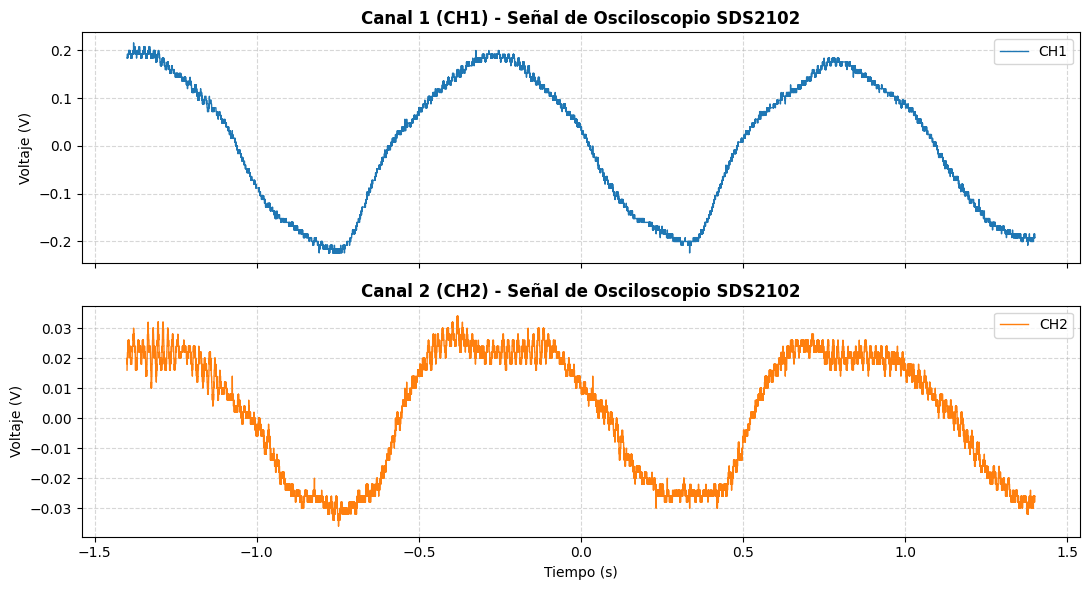

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Cargar las columnas de datos
# Las columnas 0 a 2 contienen metadatos del osciloscopio;
# las columnas 3, 4 y 5 contienen el tiempo y las lecturas de CH1 y CH2.
df = pd.read_csv(
    'SDSTEST.csv',
    skiprows=2,
    usecols=[3, 4, 5],
    names=['Time_raw', 'CH1_V', 'CH2_V'],
    dtype=float,
)

# 2. Reconstruir la escala de tiempo continua
# El osciloscopio muestrea a dt = 2 µs (0.000002 s) desde t = -1.4 s hasta +1.4 s
dt = 2e-6
t_inicio = -1.4
tiempo = t_inicio + np.arange(len(df)) * dt

# 3. Factor de submuestreo para optimizar la visualización
# Muestra 1 de cada 50 puntos (~28.000 puntos) para graficar rápido sin perder fidelidad
sub = 50

# 4. Crear los gráficos
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# Canal 1
ax1.plot(
    tiempo[::sub],
    df['CH1_V'].iloc[::sub],
    color='#1f77b4',
    linewidth=1,
    label='CH1',
)
ax1.set_title(
    'Canal 1 (CH1) - Señal de Osciloscopio SDS2102',
    fontsize=12,
    fontweight='bold',
)
ax1.set_ylabel('Voltaje (V)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right')

# Canal 2
ax2.plot(
    tiempo[::sub],
    df['CH2_V'].iloc[::sub],
    color='#ff7f0e',
    linewidth=1,
    label='CH2',
)
ax2.set_title(
    'Canal 2 (CH2) - Señal de Osciloscopio SDS2102',
    fontsize=12,
    fontweight='bold',
)
ax2.set_xlabel('Tiempo (s)', fontsize=10)
ax2.set_ylabel('Voltaje (V)', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()